# Same pattern, different story

Computing enters social science twice: as the source of data, and as a way to
turn a theory into something that runs. Both come with a warning that this
notebook makes concrete. A trend in platform data can be a trend in the platform's
software rather than in people. And a model that reproduces an observed pattern
shows that its mechanism is sufficient, not that it is the one at work, because
a different mechanism can produce the same pattern. In both cases the way out is
the same: find the observation on which the stories differ.

## 1. The trend that lived in the software

Ten thousand users post for twelve weeks. Each week, every user writes a post,
about climate with a fixed probability of 10% that never changes. Users also see
eight posts chosen by the platform and repost each with probability 20%. From
week 7 the ranking algorithm gives climate posts three times the exposure. We
record what a researcher with access to the posts would see: the share of all
posts, originals and reposts, that are about climate.

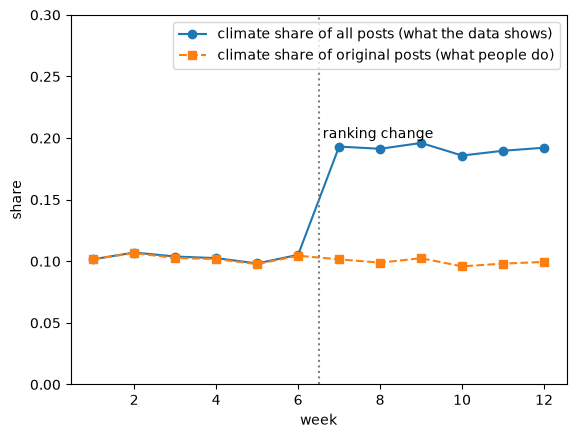

before: 0.103   after: 0.191


In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(13)

users, weeks, p_climate, seen, p_repost = 10_000, 12, 0.10, 8, 0.20
original_share, observed_share = [], []
for week in range(1, weeks + 1):
    is_climate = rng.random(users) < p_climate                    # the originals: interest never changes
    boost = 3.0 if week >= 7 else 1.0                             # the platform changes its ranking
    weights = np.where(is_climate, boost, 1.0); weights /= weights.sum()
    shown = rng.choice(users, size=(users, seen), p=weights)     # what each user gets to see
    reposted = shown[rng.random((users, seen)) < p_repost]        # which of them they repost
    n_climate = is_climate.sum() + is_climate[reposted].sum()
    original_share.append(is_climate.mean())
    observed_share.append(n_climate / (users + len(reposted)))

plt.plot(range(1, weeks + 1), observed_share, "o-", label="climate share of all posts (what the data shows)")
plt.plot(range(1, weeks + 1), original_share, "s--", label="climate share of original posts (what people do)")
plt.axvline(6.5, color="gray", linestyle=":"); plt.text(6.6, 0.2, "ranking change")
plt.ylim(0, 0.3); plt.xlabel("week"); plt.ylabel("share"); plt.legend(); plt.show()
print("before:", np.mean(observed_share[:6]).round(3), "  after:", np.mean(observed_share[6:]).round(3))

The share of climate content in the data nearly doubles at week 7, and nothing
happened to the people: the probability that a user writes about climate
is the same 10% in every week. The rise is the ranking change, amplified by
reposts. A researcher who only has the posts sees a rise in public attention that
is not there, and would find the same rise for any topic the algorithm favored.
This is algorithmic confounding. The way out is a measurement that the algorithm
cannot touch, the original posts here, or a survey outside the platform, and a
question to the platform about what changed and when.

## 2. Two mechanisms, one heavy tail

Two hundred songs, five thousand downloads. In the first model people download
what is already popular: the chance of choosing a song grows with its downloads so
far, a mechanism known as cumulative advantage or the rich-get-richer effect. In
the second, each song has a fixed
quality and people choose in proportion to it. We run both and look at the
distribution of popularity.

cumulative advantage   top 10% of songs get 31% of the downloads
fixed quality          top 10% of songs get 38% of the downloads


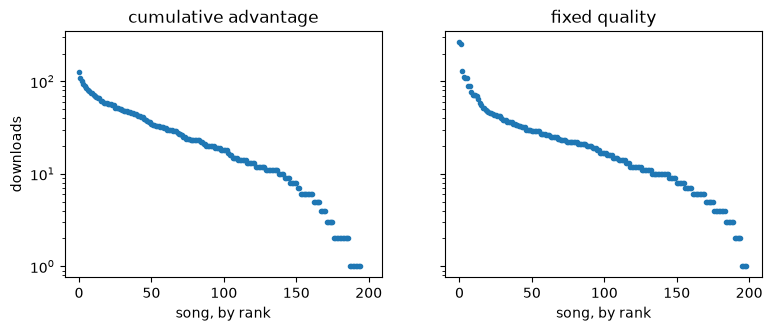

In [2]:
songs, downloads = 200, 5000
quality = rng.lognormal(0, 1, songs)

def simulate(mechanism, seed):
    r = np.random.default_rng(seed)
    count = np.zeros(songs)
    for _ in range(downloads):
        w = count + 1 if mechanism == "cumulative advantage" else quality
        count[r.choice(songs, p=w / w.sum())] += 1
    return count

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, mechanism in zip(axes, ["cumulative advantage", "fixed quality"]):
    c = simulate(mechanism, seed=1)
    ax.plot(np.sort(c)[::-1], "o", markersize=3)
    ax.set_yscale("log"); ax.set_xlabel("song, by rank"); ax.set_title(mechanism)
    print(f"{mechanism:<22} top 10% of songs get {np.sort(c)[::-1][:songs // 10].sum() / downloads:.0%} of the downloads")
axes[0].set_ylabel("downloads"); plt.show()

Both plots show the same thing: a few hits, a long tail of songs with a handful
of downloads, and the top tenth of the songs taking a third or more of the market. Having reproduced this
pattern, each model has shown that its mechanism is sufficient to generate it. But
the pattern cannot tell you which mechanism operates, and the two say opposite
things about the world: in one the hits are the best songs, in the other they are
the lucky ones. This is generative sufficiency, and its limit.

## 3. The observation that tells them apart

The models disagree about something we can check: what happens if history runs
again. We simulate each mechanism in four independent worlds, the same songs and
the same rules, only the random choices differ, and ask whether the same songs win.
This is what Salganik, Dodds and Watts did in 2006 with real listeners in parallel
online "worlds".

In [3]:
for mechanism in ["cumulative advantage", "fixed quality"]:
    worlds = np.array([simulate(mechanism, seed=s) for s in range(1, 5)])
    ranks = np.argsort(np.argsort(-worlds, axis=1), axis=1)          # rank of each song in each world
    top_sets = [set(np.argsort(-w)[:10]) for w in worlds]
    shared = len(set.intersection(*top_sets))
    corr = np.corrcoef(worlds)[np.triu_indices(4, 1)].mean()
    print(f"{mechanism:<22} correlation of popularity between worlds {corr:.2f}   "
          f"songs in the top 10 of all four worlds: {shared}")

cumulative advantage   correlation of popularity between worlds 0.03   songs in the top 10 of all four worlds: 0
fixed quality          correlation of popularity between worlds 0.98   songs in the top 10 of all four worlds: 7


Under fixed quality the four worlds agree: popularity is highly correlated across
them and the top ten is largely the same list. Under cumulative advantage the worlds
barely agree: which songs become hits depends on who downloaded first, and the same
songs end up at the top in one world and in the tail of another. One number that
looks the same in both models, the inequality of the outcome, is uninformative;
one experiment that the models predict differently decides between them. That is
the methodological cycle of the lecture in miniature: traces show the pattern, the
model states the mechanisms, and only an experiment, or an observation designed
like one, says which mechanism is real.

**What we used:** [issues with digital data: representation](../Transcripts/13-SocialScienceApplications.md#8-issues-with-digital-data-representation),
[agent-based modeling](../Transcripts/13-SocialScienceApplications.md#13-agent-based-modeling),
[combining disciplines and methods](../Transcripts/13-SocialScienceApplications.md#5-combining-disciplines-and-methods)
and [the three meanings of "computational"](../Transcripts/13-SocialScienceApplications.md#3-the-three-meanings-of-computational)
from session 13.